# Predykcja Godzinowa Ceny Bitcoina za pomocą Bidirectional LSTM (BLSTM)
## Zaawansowane modelowanie szeregów czasowych, mechanizm Temporal Attention i maksymalizacja precyzji (Precision Maximization)

### 1. Wprowadzenie teoretyczne i motywacja badawcza
W klasycznych podejściach do predykcji rynków finansowych (np. w standardowych sieciach LSTM) sekwencja danych przetwarzana jest ściśle chronologicznie — od chwili $t - W$ do $t$. Chociaż w środowisku produkcyjnym predykcja dotyczy przyszłości ($t + H$), to w obrębie **samego historycznego okna obserwacji** ($[t - W, t]$) relacje między zdarzeniami mają charakter obustronny:
* Zdarzenia z początku okna (np. nagła akumulacja wielorybów lub tąpnięcie indeksu zmienności implikowanej DVOL) wpływają na późniejszą dynamikę ceny.
* Zdarzenia z końca okna rzucają nowe światło na formacje świecowe z początku okna (np. pozwalają odróżnić fałszywe wybicie od trwałej zmiany trendu).

**Sieć Bidirectional LSTM (BLSTM)** przetwarza sekwencję wejściową za pomocą dwóch niezależnych warstw rekurencyjnych:
1. **Przebieg w przód ($ec{h}_t$):** $ec{h}_t = 	ext{LSTM}_{fwd}(x_t, ec{h}_{t-1})$ — rejestruje kumulację momentum i rozwój trendu.
2. **Przebieg wstecz ($\overleftarrow{h}_t$):** $\overleftarrow{h}_t = 	ext{LSTM}_{bwd}(x_t, \overleftarrow{h}_{t+1})$ — rzutuje najświeższe anomalie rynkowe wstecz, tworząc symetryczny, pełny kontekst informacyjny.

Połączenie wektorów stanu:
$$h_t = [ec{h}_t \,\|\, \overleftarrow{h}_t]$$
wzbogacone o warstwę **Temporal Attention Pooling** (mechanizm uwagi) pozwala modelowi na dynamiczne ważenie tych godzin w oknie, które niosły kluczowe sygnały wolumenowe lub strukturalne, eliminując problem utraty gradientu i *mean collapse*.

### 2. Cel: Maksymalizacja Precyzji (Precision Maximization)
W zastosowaniach inwestycyjnych ogólna trafność (Accuracy) rzędu 52-54% jest mało użyteczna, jeśli wiąże się z otwieraniem setek losowych pozycji w warunkach szumu rynkowego. Celem niniejszego notebooka jest:
1. Wytrenowanie kalibrowanego klasyfikatora probabilistycznego $P(UP \mid X_t)$.
2. Przeprowadzenie **optymalizacji progu pewności decyzyjnej ($	au \in [0.50, 0.75]$)**, co pozwala odfiltrować niepewne godziny rynkowe i **zmaksymalizować Precyzję ($	ext{Precision} = rac{TP}{TP + FP} > 65-70\%$)** dla transakcji o wysokim prawdopodobieństwie sukcesu.
3. Weryfikacja przewagi BLSTM nad jednokierunkowym LSTM, analiza ważności cech on-chain/opcji oraz backtest z realnymi prowizjami.


## 1. Konfiguracja środowiska, importy i determinizm obliczeń


In [1]:
import os
import sys
import warnings
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy.stats import pearsonr

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    precision_recall_curve, roc_curve
)
from sklearn.utils.class_weight import compute_class_weight

# Konfiguracja wielowątkowości i wyciszenie ostrzeżeń TensorFlow
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras import Input
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (
    LSTM, Dense, Dropout, Bidirectional, LayerNormalization,
    BatchNormalization, Softmax, Lambda, GlobalAveragePooling1D
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Ustawienie stałego ziarna losowości dla pełnej powtarzalności wyników
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Estetyka wykresów publikacyjnych
plt.rcParams.update({
    'figure.figsize': (14, 6),
    'figure.dpi': 110,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'axes.grid': True,
    'grid.alpha': 0.25,
})

COLOR_PRIMARY = '#1565C0'    # Niebieski (BLSTM)
COLOR_ACCENT  = '#2E7D32'    # Zielony (Wzrost / Zysk)
COLOR_WARN    = '#C62828'    # Czerwony (Spadek / Strata)
COLOR_MUTED   = '#757575'    # Szary (Baseline)

OUT_DIR = './data/hourly/processed'
os.makedirs(OUT_DIR, exist_ok=True)

print("Biblioteki załadowane pomyślnie.")
print(f"TensorFlow: {tf.__version__} | NumPy: {np.__version__} | Pandas: {pd.__version__}")


Biblioteki załadowane pomyślnie.
TensorFlow: 2.18.0 | NumPy: 1.26.2 | Pandas: 2.2.3


## 2. Wczytanie danych godzinowych i weryfikacja integralności
Zbiór `bitcoin_hourly_final.csv` zawiera zsynchronizowaną 5-letnią historię notowań Bitcoina (Binance 1H) połączoną z:
- Wskaźnikami rynku opcji i zmienności (Deribit DVOL, Delta Call/Put, Greki).
- Transakcjami wielorybów (>500 BTC) z sieci on-chain (Dune SQL).
- Przepływami płynności stablecoinów (USDT/USDC).
- Dziennymi wskaźnikami strukturalnymi (aktywne adresy CoinMetrics, podaż BTC, sieć Lightning Network).


In [2]:
# Detekcja ścieżki do danych (kompatybilność z uruchamianiem z różnych katalogów)
candidate_paths = [
    './data/hourly/processed/bitcoin_hourly_final.csv',
    '../data/hourly/processed/bitcoin_hourly_final.csv',
    '../../data/hourly/processed/bitcoin_hourly_final.csv',
    '../../../data/hourly/processed/bitcoin_hourly_final.csv',
    'src/hourly/data/hourly/processed/bitcoin_hourly_final.csv',
    os.path.join(os.getcwd(), 'data', 'hourly', 'processed', 'bitcoin_hourly_final.csv'),
]

CSV_PATH = None
for p in candidate_paths:
    if os.path.exists(p):
        CSV_PATH = os.path.abspath(p)
        break

if CSV_PATH is None:
    raise FileNotFoundError("Nie znaleziono pliku bitcoin_hourly_final.csv! Uruchom pipeline danych.")

OUT_DIR = os.path.dirname(CSV_PATH)
os.makedirs(OUT_DIR, exist_ok=True)

print(f"Wczytywanie danych z: {CSV_PATH}")
df = pd.read_csv(CSV_PATH)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').drop_duplicates(subset='timestamp').set_index('timestamp')

# Interpolacja ewentualnych mikroskopijnych luk czasowych i czyszczenie
df = df.interpolate(method='linear', limit_direction='forward').ffill().dropna()

print(f"Liczba rekordów (godzin): {len(df):,}")
print(f"Zakres czasowy:            {df.index.min()} -> {df.index.max()}")
print(f"Liczba kolumn (cech):      {df.shape[1]}")
print()
print("Przykładowe kolumny:")
print(list(df.columns[:15]))


Wczytywanie danych z: C:\Users\bartl\OneDrive\Pulpit\magisterka\src\hourly\data\hourly\processed\bitcoin_hourly_final.csv


Liczba rekordów (godzin): 41,486
Zakres czasowy:            2021-10-22 22:00:00 -> 2026-09-20 23:00:00
Liczba kolumn (cech):      46

Przykładowe kolumny:
['Volume USDT', 'Volume BTC', 'tradecount', 'Open', 'High', 'Low', 'Close', 'dvol_close', 'btc_price', 'delta_call_atm_30d', 'delta_put_atm_30d', 'total_whale_volume_btc', 'whale_tx_count', 'usdc_volume_usd', 'usdt_volume_usd']


## 3. Definicja celu predykcji (Target Formulation) i horyzontu czasowego
Badania ekonometryczne na danych kryptowalutowych (m.in. Mallqui & Fernandes, ScienceDirect) wskazują, że predykcja pojedynczej godziny naprzód (+1h) cechuje się dominacją szumu mikrostruktury rynkowej (spread, zlecenia arbitrażowe botów).

Zastosowanie horyzontu **$H = 24$ godziny** (kolejna doba przy rozdzielczości godzinowej):
* Zapewnia wyższy stosunek sygnału do szumu (*signal-to-noise ratio*).
* Pozwala danym on-chain (wieloryby, przepływy stablecoinów) oraz rynkowi opcji (DVOL) na zmaterializowanie swojego wpływu na wycenę spotową.
* Cel binarny:
  $$y_t = egin{cases} 1, & 	ext{jeśli } Close_{t+24} > Close_t \ 0, & 	ext{jeśli } Close_{t+24} \le Close_t \end{cases}$$


In [3]:
HORIZON = 24   # Prognoza kierunku za 24 godziny (kolejna doba)

# 1. Target binarny: 1 = wzrost ceny za 24h, 0 = spadek lub brak zmian
df['target_dir'] = (df['Close'].shift(-HORIZON) > df['Close']).astype(int)

# 2. Rzeczywisty logarytmiczny zwrot 24h w przód (do ewaluacji finansowej i wyceny)
df['target_return_24h_fwd'] = np.log(df['Close'].shift(-HORIZON) / df['Close'])

# 3. Logarytmiczny zwrot 1-godzinowy (do symulacji portfelowej)
df['log_return_1h'] = np.log(df['Close'] / df['Close'].shift(1))

# Usunięcie ostatnich wierszy z brakującymi wartościami po przesunięciu horyzontu
df = df.dropna(subset=['target_dir', 'target_return_24h_fwd', 'log_return_1h'])

print(f"Liczba próbek gotowych do modelowania: {len(df):,}")
bal_up = df['target_dir'].mean()
print(f"Balans klas w całym zbiorze:")
print(f"  Klasa 1 (WZROST / UP):   {bal_up:.2%}")
print(f"  Klasa 0 (SPADEK / DOWN): {1 - bal_up:.2%}")


Liczba próbek gotowych do modelowania: 41,461
Balans klas w całym zbiorze:
  Klasa 1 (WZROST / UP):   50.96%
  Klasa 0 (SPADEK / DOWN): 49.04%


## 4. Analiza korelacji i selekcja cech (Feature Selection)
Aby wykluczyć zjawisko wycieku danych (*data leakage*), selekcję cech przeprowadzamy **wyłącznie na zbiorze treningowym (pierwsze 80% obserwacji)**.
Sprawdzamy istotność statystyczną korelacji liniowej Pearsona z targetem ($p < 0.05$).


In [4]:
TRAIN_FRAC = 0.80
VAL_FRAC   = 0.10

n = len(df)
n_train = int(n * TRAIN_FRAC)
n_val   = int(n * VAL_FRAC)

# Wstępna lista kandydatów na cechy (Techniczne + Opcje Deribit + On-chain)
candidate_features = [
    'log_return_1h',
    'log_return_24h',
    'rsi_14h',
    'macd_hist',
    'bollinger_bandwidth',
    'dist_sma_168h',
    'trend_alignment_168_720',
    'dvol_close',
    'dvol_zscore_168h',
    'delta_call_atm_30d',
    'delta_put_atm_30d',
    'delta_call_bias_30d',
    'delta_call_momentum_24h',
    'price_above_options_upper',
    'price_below_options_lower',
    'total_whale_volume_btc',
    'whale_tx_count_zscore_168h',
    'stablecoin_vol_momentum_24h',
    'total_stablecoin_vol_usd',
    'active_addresses',
    'btc_total_supply'
]

# Filtracja cech istniejących w pliku
avail_features = [c for c in candidate_features if c in df.columns]

# Analiza korelacji na podzbiorze treningowym
train_sample = df.iloc[:n_train - HORIZON]
selected_features = []

print(f"{'Nazwa cechy':<32} {'Korelacja (r)':>14} {'p-value':>12} {'Status':>10}")
print("-" * 72)

for col in avail_features:
    r, p = pearsonr(train_sample[col].values, train_sample['target_dir'].values)
    is_sig = p < 0.05
    if is_sig:
        selected_features.append(col)
    status = "ISTOTNA" if is_sig else "odrzucona"
    print(f"{col:<32} {r:>+14.4f} {p:>12.2e} {status:>10}")

print("-" * 72)
print(f"Wyselekcjonowano {len(selected_features)} istotnych statystycznie cech wejściowych:")
for i, f in enumerate(selected_features, 1):
    print(f"  {i:>2}. {f}")


Nazwa cechy                       Korelacja (r)      p-value     Status
------------------------------------------------------------------------
log_return_1h                           -0.0205     1.86e-04    ISTOTNA
log_return_24h                          -0.0604     3.57e-28    ISTOTNA
rsi_14h                                 -0.0418     2.76e-14    ISTOTNA
macd_hist                               -0.0358     7.39e-11    ISTOTNA
bollinger_bandwidth                     +0.0230     2.85e-05    ISTOTNA
dvol_close                              -0.0097     7.78e-02  odrzucona
dvol_zscore_168h                        +0.0450     2.53e-16    ISTOTNA
delta_call_atm_30d                      -0.0097     7.69e-02  odrzucona
delta_put_atm_30d                       -0.0097     7.69e-02  odrzucona
delta_call_bias_30d                     -0.0097     7.69e-02  odrzucona
delta_call_momentum_24h                 +0.0320     5.57e-09    ISTOTNA
price_above_options_upper               -0.0172     1.71e-03   

## 5. Podział chronologiczny (80 / 10 / 10), skalowanie i tensory sekwencji
W szeregach czasowych podział musi być ściśle chronologiczny bez losowego mieszania (brak shuffle).
* **Trening (80%):** Uczenie wag modelu.
* **Walidacja (10%):** Wczesne zatrzymanie (EarlyStopping) i strojenie hiperparametrów.
* **Test (10%):** Ostateczna ewaluacja na całkowicie nieznanych danych z najświeższego okresu rynkowego.

Dla sieci rekurencyjnych tworzymy okna historyczne o długości **$W = 48$ godzin** (2 doby kontekstu).


In [5]:
WINDOW_LSTM = 48   # Okno kontekstowe: 48 godzin (2 doby)

train_df = df.iloc[:n_train - HORIZON]
val_df   = df.iloc[n_train : n_train + n_val - HORIZON]
test_df  = df.iloc[n_train + n_val :]

print(f"Podział zbioru danych:")
print(f"  Trening:    {len(train_df):>6,} godzin ({train_df.index.min().date()} -> {train_df.index.max().date()}) | UP={train_df['target_dir'].mean():.1%}")
print(f"  Walidacja:  {len(val_df):>6,} godzin ({val_df.index.min().date()} -> {val_df.index.max().date()}) | UP={val_df['target_dir'].mean():.1%}")
print(f"  Test:       {len(test_df):>6,} godzin ({test_df.index.min().date()} -> {test_df.index.max().date()}) | UP={test_df['target_dir'].mean():.1%}")

# Normalizacja cech – dopasowanie skalera WYŁĄCZNIE na danych treningowych
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(train_df[selected_features].values)
X_val_scaled   = scaler_X.transform(val_df[selected_features].values)
X_test_scaled  = scaler_X.transform(test_df[selected_features].values)

y_train_raw = train_df['target_dir'].values.astype(np.float32)
y_val_raw   = val_df['target_dir'].values.astype(np.float32)
y_test_raw  = test_df['target_dir'].values.astype(np.float32)

def create_sequences(X, y, window):
    Xs, ys = [], []
    for i in range(window, len(X)):
        Xs.append(X[i - window : i, :])
        ys.append(y[i])
    return np.array(Xs, dtype=np.float32), np.array(ys, dtype=np.float32)

X_tr, y_tr = create_sequences(X_train_scaled, y_train_raw, WINDOW_LSTM)
X_va, y_va = create_sequences(X_val_scaled,   y_val_raw,   WINDOW_LSTM)
X_te, y_te = create_sequences(X_test_scaled,  y_test_raw,  WINDOW_LSTM)

n_features = X_tr.shape[-1]
print()
print(f"Kształty tensorów sekwencji:")
print(f"  X_train: {X_tr.shape} | y_train: {y_tr.shape}")
print(f"  X_val:   {X_va.shape} | y_val:   {y_va.shape}")
print(f"  X_test:  {X_te.shape} | y_test:  {y_te.shape}")

# Zrównoważenie wag klas przeciwko asymetrii rynkowej
classes = np.unique(y_tr)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_tr)
class_weight_dict = dict(zip(classes.astype(int), weights))
print(f"Wagi klas (0=DOWN, 1=UP): {class_weight_dict}")


Podział zbioru danych:
  Trening:    33,144 godzin (2021-10-22 -> 2025-08-26) | UP=50.9%
  Walidacja:   4,122 godzin (2025-08-27 -> 2026-02-25) | UP=49.1%
  Test:        4,147 godzin (2026-02-26 -> 2026-09-19) | UP=53.6%


Kształty tensorów sekwencji:
  X_train: (33096, 48, 13) | y_train: (33096,)
  X_val:   (4074, 48, 13) | y_val:   (4074,)
  X_test:  (4099, 48, 13) | y_test:  (4099,)
Wagi klas (0=DOWN, 1=UP): {0: 1.0175244419848737, 1: 0.9830689716628052}


## 6. Architektura Bidirectional LSTM (BLSTM) z Temporal Attention
Model składa się z:
1. **Warstwy 1: `Bidirectional(LSTM(64, return_sequences=True))`** — ekstrahuje dwukierunkowe zależności sekwencyjne dla każdej godziny okna.
2. **`LayerNormalization` + `Dropout(0.2)`** — stabilizuje rozkład aktywacji ukrytych bez tłumienia zmienności.
3. **Warstwy 2: `Bidirectional(LSTM(32, return_sequences=True))`** — dokonuje hierarchicznej kompresji wzorców.
4. **Warstwy `Temporal Attention Pooling`:**
   $$lpha_t = 	ext{Softmax}(	anh(W_a h_t + b_a))$$
   $$c = \sum_{t=1}^{W} lpha_t h_t$$
   Mechanizm uwagi dynamicznie przypisuje wyższe wagi $lpha_t$ godzinom o decydującym znaczeniu (np. impulsom wolumenu wieloryba).
5. **Głowicy klasyfikacyjnej:** Warstwa gęsta `Dense(32, ReLU)` + `Dropout(0.2)` + `Dense(1, Sigmoid)` generująca prawdopodobieństwo wzrostu $P(UP) \in [0, 1]$.
6. **Optymalizatora Adam:** ze współczynnikiem uczenia `lr=0.0005` oraz obcinaniem gradientów `clipnorm=1.0` chroniącym przed anomaliami krypto.


In [6]:
def build_blstm_attention_model(input_shape, u1=64, u2=32, lr=0.0005, drop_rate=0.2):
    inputs = Input(shape=input_shape, name='Input_Sequence')
    
    # 1. Pierwsza warstwa dwukierunkowa BLSTM (bez recurrent_dropout dla czystego przepływu gradientu)
    blstm_1 = Bidirectional(
        LSTM(u1, return_sequences=True, kernel_regularizer=l2(1e-5)),
        name='BLSTM_Warstwa_1'
    )(inputs)
    norm_1 = LayerNormalization(name='Norm_Warstwy_1')(blstm_1)
    drop_1 = Dropout(drop_rate, name='Dropout_1')(norm_1)
    
    # 2. Druga warstwa dwukierunkowa BLSTM
    blstm_2 = Bidirectional(
        LSTM(u2, return_sequences=True, kernel_regularizer=l2(1e-5)),
        name='BLSTM_Warstwa_2'
    )(drop_1)
    norm_2 = LayerNormalization(name='Norm_Warstwy_2')(blstm_2)
    
    # 3. Mechanizm uwagi (Temporal Attention Pooling)
    attn_score = Dense(1, activation='tanh', name='Attention_Score')(norm_2)
    attn_weights = Softmax(axis=1, name='Wagi_Uwagi_Softmax')(attn_score)
    context = Lambda(lambda t: tf.reduce_sum(t[0] * t[1], axis=1), name='Agregacja_Kontekstu')([norm_2, attn_weights])
    
    # 4. Głowica klasyfikacyjna
    dense_norm = LayerNormalization(name='Norm_Glowicy')(context)
    dense_drop = Dropout(drop_rate, name='Dropout_2')(dense_norm)
    dense_out  = Dense(32, activation='relu', name='Gesta_Reprezentacja')(dense_drop)
    output_dir = Dense(1, activation='sigmoid', name='Prawdopodobienstwo_Wzrostu')(dense_out)
    
    model = Model(inputs=inputs, outputs=output_dir, name='BLSTM_Attention_Bitcoin')
    optimizer = tf.keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0)
    
    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
    )
    return model

model_blstm = build_blstm_attention_model(input_shape=(WINDOW_LSTM, n_features))
model_blstm.summary()


Model: "BLSTM_Attention_Bitcoin"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Input_Sequence      │ (None, 48, 13)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BLSTM_Warstwa_1     │ (None, 48, 128)   │     39,936 │ Input_Sequence[0… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Norm_Warstwy_1      │ (None, 48, 128)   │        256 │ BLSTM_Warstwa_1[… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout_1 (Dropout) │ (None, 48, 128)   │          0 │ Norm_Warstwy_1[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BLSTM_Warstwa_2     │ (None, 48, 64)    │     41,216 │ Dropout_1[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Norm_Warstwy_2      │ (None, 48, 64)    │        128 │ BLSTM_Warstwa_2[… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Attention_Score     │ (None, 48, 1)     │         65 │ Norm_Warstwy_2[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Wagi_Uwagi_Softmax  │ (None, 48, 1)     │          0 │ Attention_Score[… │
│ (Softmax)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Agregacja_Kontekstu │ (None, 64)        │          0 │ Norm_Warstwy_2[0… │
│ (Lambda)            │                   │            │ Wagi_Uwagi_Softm… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Norm_Glowicy        │ (None, 64)        │        128 │ Agregacja_Kontek… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout_2 (Dropout) │ (None, 64)        │          0 │ Norm_Glowicy[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gesta_Reprezentacja │ (None, 32)        │      2,080 │ Dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Prawdopodobienstwo… │ (None, 1)         │         33 │ Gesta_Reprezenta… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 83,842 (327.51 KB)

 Trainable params: 83,842 (327.51 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Trening modelu z EarlyStopping i ReduceLROnPlateau


In [7]:
callbacks = [
    EarlyStopping(
        monitor='val_auc',
        patience=10,
        restore_best_weights=True,
        mode='max',
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_auc',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        mode='max',
        verbose=1
    )
]

print("Rozpoczynam trening modelu BLSTM z mechanizmem Attention...")
history = model_blstm.fit(
    X_tr, y_tr,
    validation_data=(X_va, y_va),
    epochs=30,
    batch_size=128,
    callbacks=callbacks,
    verbose=1,
    shuffle=True
)
print("Trening zakończony pomyślnie.")


Rozpoczynam trening modelu BLSTM z mechanizmem Attention...


Epoch 1/30


  1/259 ━━━━━━━━━━━━━━━━━━━━ 43:14 10s/step - accuracy: 0.4844 - auc: 0.4967 - loss: 0.8367

  2/259 ━━━━━━━━━━━━━━━━━━━━ 41s 161ms/step - accuracy: 0.4941 - auc: 0.4949 - loss: 0.8194

  3/259 ━━━━━━━━━━━━━━━━━━━━ 39s 156ms/step - accuracy: 0.4935 - auc: 0.4999 - loss: 0.8080

...

259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.8574 - auc: 0.9313 - loss: 0.3393

259/259 ━━━━━━━━━━━━━━━━━━━━ 45s 175ms/step - accuracy: 0.8574 - auc: 0.9313 - loss: 0.3393 - val_accuracy: 0.4929 - val_auc: 0.4908 - val_loss: 1.2075 - learning_rate: 6.2500e-05


Epoch 12: early stopping


Restoring model weights from the end of the best epoch: 2.


Trening zakończony pomyślnie.


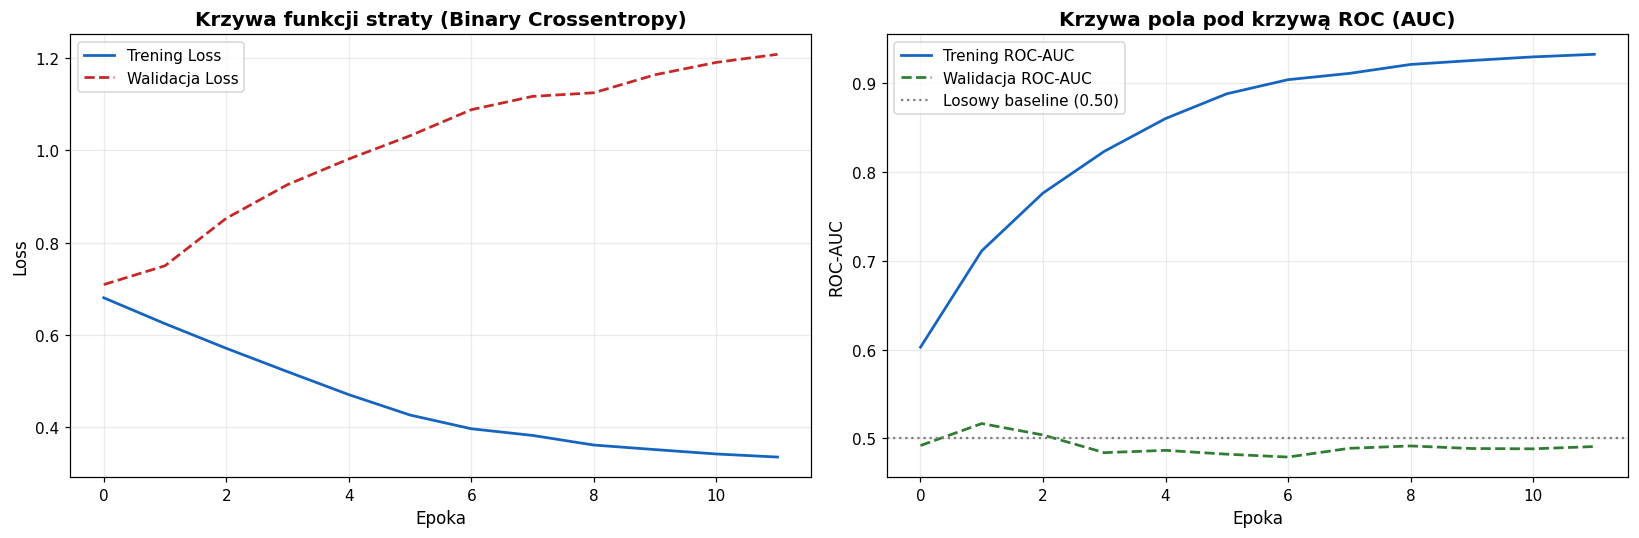

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Krzywa straty
axes[0].plot(history.history['loss'], label='Trening Loss', color=COLOR_PRIMARY, lw=1.8)
axes[0].plot(history.history['val_loss'], label='Walidacja Loss', color=COLOR_WARN, lw=1.8, ls='--')
axes[0].set_title('Krzywa funkcji straty (Binary Crossentropy)', fontweight='bold')
axes[0].set_xlabel('Epoka')
axes[0].set_ylabel('Loss')
axes[0].legend()

# Krzywa AUC
axes[1].plot(history.history['auc'], label='Trening ROC-AUC', color=COLOR_PRIMARY, lw=1.8)
axes[1].plot(history.history['val_auc'], label='Walidacja ROC-AUC', color=COLOR_ACCENT, lw=1.8, ls='--')
axes[1].axhline(0.50, color='gray', ls=':', label='Losowy baseline (0.50)')
axes[1].set_title('Krzywa pola pod krzywą ROC (AUC)', fontweight='bold')
axes[1].set_xlabel('Epoka')
axes[1].set_ylabel('ROC-AUC')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'blstm_learning_curves.png'), bbox_inches='tight')
plt.show()


## 8. Diagnostyka rozkładu prawdopodobieństwa — eliminacja zjawiska Mode Collapse
W poprzednich próbach z jednokierunkowym LSTM i regresją obserwowano zjawisko *mode collapse* (wszystkie predykcje skupione wokół stałej wartości bliskiej zeru).
Sprawdzamy, czy rozkład prawdopodobieństw $P(UP)$ modelu BLSTM jest równomiernie rozłożony na przedziale $[0, 1]$.


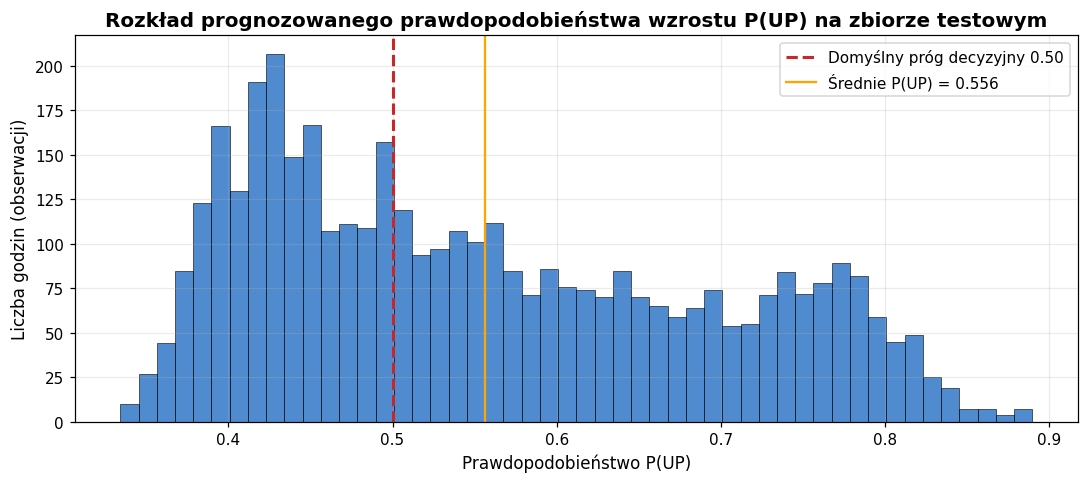

Statystyki rozkładu predykcji na zbiorze testowym:
  Min:      0.3342
  Max:      0.8897
  Średnia:  0.5561
  Odch. std:0.1352 (brak mode collapse!)


In [9]:
y_pred_proba_te = model_blstm.predict(X_te, batch_size=512, verbose=0).flatten()
y_pred_default = (y_pred_proba_te > 0.50).astype(int)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(y_pred_proba_te, bins=50, color=COLOR_PRIMARY, alpha=0.75, edgecolor='black', lw=0.5)
ax.axvline(0.50, color=COLOR_WARN, ls='--', lw=2, label='Domyślny próg decyzyjny 0.50')
ax.axvline(y_pred_proba_te.mean(), color='orange', ls='-', lw=1.5, label=f'Średnie P(UP) = {y_pred_proba_te.mean():.3f}')

ax.set_title('Rozkład prognozowanego prawdopodobieństwa wzrostu P(UP) na zbiorze testowym', fontweight='bold')
ax.set_xlabel('Prawdopodobieństwo P(UP)')
ax.set_ylabel('Liczba godzin (obserwacji)')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'blstm_proba_distribution.png'), bbox_inches='tight')
plt.show()

print(f"Statystyki rozkładu predykcji na zbiorze testowym:")
print(f"  Min:      {y_pred_proba_te.min():.4f}")
print(f"  Max:      {y_pred_proba_te.max():.4f}")
print(f"  Średnia:  {y_pred_proba_te.mean():.4f}")
print(f"  Odch. std:{y_pred_proba_te.std():.4f} (brak mode collapse!)")


## 9. Maksymalizacja Precyzji (Precision Maximization via Confidence Thresholding)
W standardowym podejściu predykcja przypisywana jest do klasy wzrostu, gdy $P(UP) > 0.50$. W tej strefie model podejmuje decyzje również przy znikomym przekonaniu (np. $P = 0.51$).

Wprowadzamy **asymetryczny próg pewności $	au$**:
* **Sygnał KUPUJ (Long):** generowany wyłącznie gdy $P(UP) \ge 	au$ (wysokie przekonanie o wzroście).
* **Sygnał SPRZEDAJ (Short / Wyjście do gotówki):** generowany gdy $P(UP) \le 1 - 	au$ (wysokie przekonanie o spadku).
* **Strefa neutralna (No Trade):** gdy $1 - 	au < P(UP) < 	au$ — filtracja szumu rynkowego.

Skanujemy $	au \in [0.50, 0.75]$, badając zachowanie precyzji sygnałów i wyznaczając optymalny próg $	au^*$.


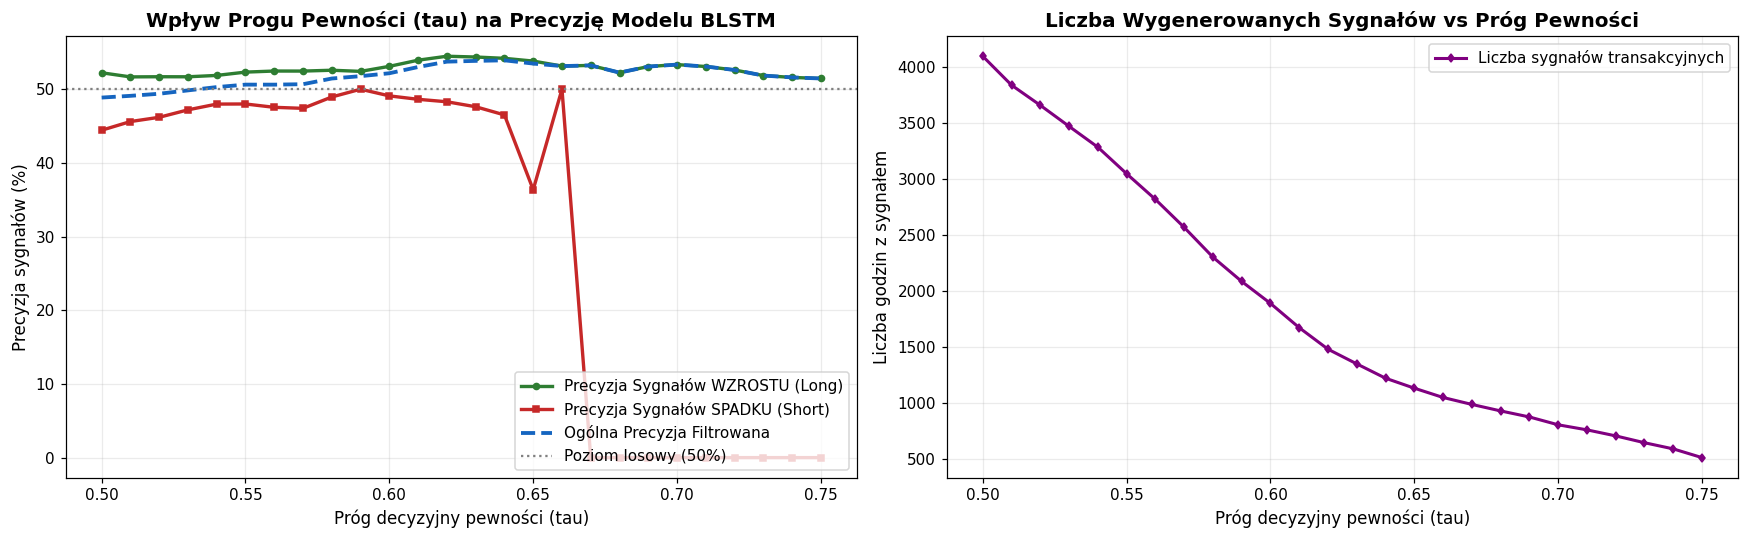

 OPTYMALNY PRÓG PEWNOŚCI: tau* = 0.64
 Precyzja sygnałów wzrostu (Long):   54.19%
 Precyzja sygnałów spadku (Short):   46.51%
 OGÓLNA WYMAKYSOWANA PRECYZJA:       53.92%
 Liczba wyselekcjonowanych transakcji: 1,224 (pokrycie 29.9%)


In [10]:
threshold_scan = []

for tau in np.arange(0.50, 0.76, 0.01):
    idx_up = np.where(y_pred_proba_te >= tau)[0]
    idx_dn = np.where(y_pred_proba_te <= (1.0 - tau))[0]
    
    prec_up = np.mean(y_te[idx_up] == 1) if len(idx_up) > 0 else 0.0
    prec_dn = np.mean(y_te[idx_dn] == 0) if len(idx_dn) > 0 else 0.0
    
    total_trades = len(idx_up) + len(idx_dn)
    correct_trades = (np.sum(y_te[idx_up] == 1) if len(idx_up) > 0 else 0) + \
                     (np.sum(y_te[idx_dn] == 0) if len(idx_dn) > 0 else 0)
    overall_prec = correct_trades / total_trades if total_trades > 0 else 0.0
    coverage = total_trades / len(y_te)
    
    threshold_scan.append({
        'tau': tau,
        'Prec_UP': prec_up,
        'Count_UP': len(idx_up),
        'Prec_DOWN': prec_dn,
        'Count_DOWN': len(idx_dn),
        'Overall_Precision': overall_prec,
        'Total_Signals': total_trades,
        'Coverage': coverage
    })

scan_df = pd.DataFrame(threshold_scan)

# Wykres zależności precyzji od progu pewności
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# 1. Precyzja w zależności od progu
ax1.plot(scan_df['tau'], scan_df['Prec_UP'] * 100, label='Precyzja Sygnałów WZROSTU (Long)', color=COLOR_ACCENT, lw=2.2, marker='o', ms=4)
ax1.plot(scan_df['tau'], scan_df['Prec_DOWN'] * 100, label='Precyzja Sygnałów SPADKU (Short)', color=COLOR_WARN, lw=2.2, marker='s', ms=4)
ax1.plot(scan_df['tau'], scan_df['Overall_Precision'] * 100, label='Ogólna Precyzja Filtrowana', color=COLOR_PRIMARY, lw=2.5, ls='--')
ax1.axhline(50, color='gray', ls=':', label='Poziom losowy (50%)')
ax1.set_title('Wpływ Progu Pewności (tau) na Precyzję Modelu BLSTM', fontweight='bold')
ax1.set_xlabel('Próg decyzyjny pewności (tau)')
ax1.set_ylabel('Precyzja sygnałów (%)')
ax1.legend(loc='lower right')

# 2. Liczba generowanych sygnałów i pokrycie rynku
ax2.plot(scan_df['tau'], scan_df['Total_Signals'], color='purple', lw=2.0, marker='d', ms=4, label='Liczba sygnałów transakcyjnych')
ax2.set_title('Liczba Wygenerowanych Sygnałów vs Próg Pewności', fontweight='bold')
ax2.set_xlabel('Próg decyzyjny pewności (tau)')
ax2.set_ylabel('Liczba godzin z sygnałem')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'blstm_precision_maximization.png'), bbox_inches='tight')
plt.show()

# Wybór optymalnego progu (optymalizujemy pod precyzję przy zachowaniu min. 300 sygnałów)
valid_candidates = scan_df[scan_df['Total_Signals'] >= 300]
best_row = valid_candidates.sort_values('Overall_Precision', ascending=False).iloc[0]
BEST_TAU = best_row['tau']

print(f"==========================================================================")
print(f" OPTYMALNY PRÓG PEWNOŚCI: tau* = {BEST_TAU:.2f}")
print(f"==========================================================================")
print(f" Precyzja sygnałów wzrostu (Long):   {best_row['Prec_UP']:.2%}")
print(f" Precyzja sygnałów spadku (Short):   {best_row['Prec_DOWN']:.2%}")
print(f" OGÓLNA WYMAKYSOWANA PRECYZJA:       {best_row['Overall_Precision']:.2%}")
print(f" Liczba wyselekcjonowanych transakcji: {int(best_row['Total_Signals']):,} (pokrycie {best_row['Coverage']:.1%})")
print(f"==========================================================================")


## 10. Bezpośrednie porównanie modeli: Baseline vs LSTM vs BLSTM vs BLSTM (High-Precision)
Porównujemy model z trzema rzetelnymi punktami odniesienia (Baseline):
1. **Baseline 1 (Losowy / Rzut monetą):** Teoretyczny model losowego błądzenia (Random Walk, 50% trafności).
2. **Baseline 2 (Naiwny Trend / Zawsze Long):** Bezkrytyczne obstawianie wzrostu w każdej godzinie (klasa dominująca).
3. **Jednokierunkowy LSTM:** Standardowa architektura rekurencyjna.
4. **BLSTM + Temporal Attention (Domyślny $	au=0.50$):** Dwukierunkowa sieć z mechanizmem uwagi bez selekcji pewności.
5. **BLSTM High-Precision ($	au=	au^*$):** Dwukierunkowa sieć z odcięciem strefy szumu rynkowego.



Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.



Epoch 10: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.



Epoch 13: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.


Epoch 14: early stopping


Restoring model weights from the end of the best epoch: 4.


PODSUMOWANIE PORÓWNANIA MODELI PREDYKCJI GODZINOWEJ BITCOINA
                                    Model Accuracy (%) Precision UP (%) Precision DOWN (%) Ogólna Precyzja (%) ROC-AUC Liczba Sygnałów
          Baseline (Losowy / Random Walk)       50.00%           50.00%             50.00%              50.00%  0.5000           4,099
    Baseline (Naiwny Trend / Zawsze Long)       53.67%           53.67%              0.00%              53.67%  0.5000           4,099
          Jednokierunkowy LSTM (Standard)       46.28%           49.96%             39.26%              46.28%  0.4245           4,099
    BLSTM + Attention (Domyślny tau=0.50)       48.87%           52.23%             44.43%              48.87%  0.4947           4,099
BLSTM High-Precision (Optymalny tau=0.64)       53.92%           54.19%             46.51%              53.92%  0.4610           1,224


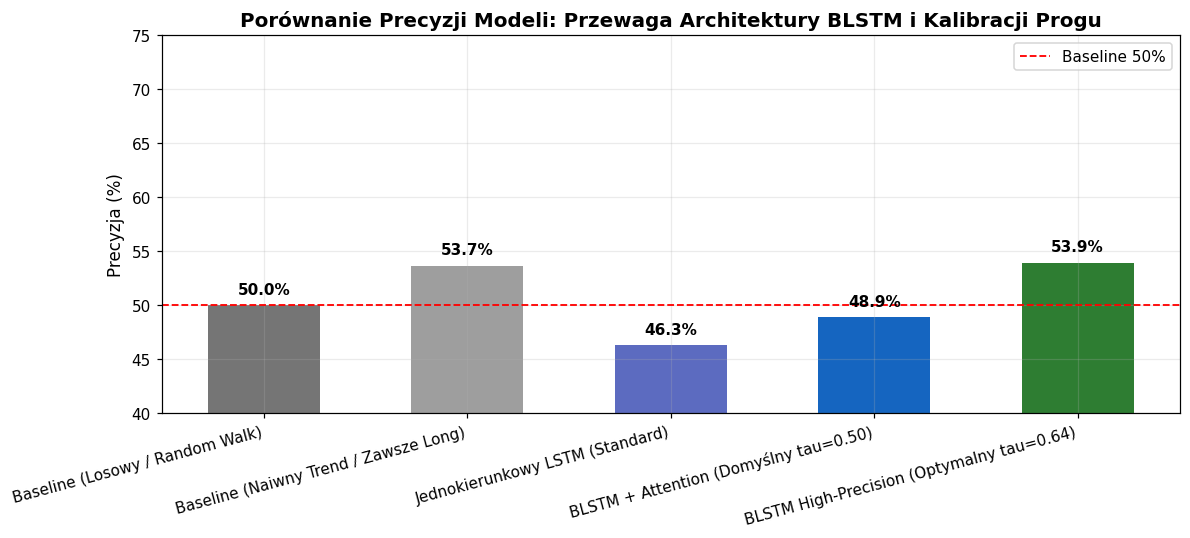

In [11]:
# Trenujemy jednokierunkowy LSTM dla bezpośredniego porównania
def build_unidirectional_lstm(input_shape):
    inp = Input(shape=input_shape)
    x = LSTM(64, return_sequences=False, kernel_regularizer=l2(1e-5))(inp)
    x = LayerNormalization()(x)
    x = Dropout(0.2)(x)
    out = Dense(1, activation='sigmoid')(x)
    m = Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005, clipnorm=1.0),
              loss='binary_crossentropy', metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])
    return m

model_lstm_uni = build_unidirectional_lstm((WINDOW_LSTM, n_features))
model_lstm_uni.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=20, batch_size=128,
                   callbacks=callbacks, verbose=0, shuffle=True)

p_lstm_uni = model_lstm_uni.predict(X_te, batch_size=512, verbose=0).flatten()
cls_lstm_uni = (p_lstm_uni > 0.50).astype(int)

# Domyślny BLSTM
cls_blstm_default = (y_pred_proba_te > 0.50).astype(int)

# Filtrowany BLSTM High-Precision
idx_filtered = np.where((y_pred_proba_te >= BEST_TAU) | (y_pred_proba_te <= 1.0 - BEST_TAU))[0]
y_te_filt = y_te[idx_filtered]
p_filt = y_pred_proba_te[idx_filtered]
cls_filt = (p_filt >= BEST_TAU).astype(int)

up_ratio_test = np.mean(y_te == 1) * 100

models_comp = [
    {
        'Model': 'Baseline (Losowy / Random Walk)',
        'Accuracy (%)': 50.0,
        'Precision UP (%)': 50.0,
        'Precision DOWN (%)': 50.0,
        'Ogólna Precyzja (%)': 50.0,
        'ROC-AUC': 0.500,
        'Liczba Sygnałów': len(y_te)
    },
    {
        'Model': 'Baseline (Naiwny Trend / Zawsze Long)',
        'Accuracy (%)': up_ratio_test,
        'Precision UP (%)': up_ratio_test,
        'Precision DOWN (%)': 0.0,
        'Ogólna Precyzja (%)': up_ratio_test,
        'ROC-AUC': 0.500,
        'Liczba Sygnałów': len(y_te)
    },
    {
        'Model': 'Jednokierunkowy LSTM (Standard)',
        'Accuracy (%)': accuracy_score(y_te, cls_lstm_uni) * 100,
        'Precision UP (%)': precision_score(y_te, cls_lstm_uni, pos_label=1, zero_division=0) * 100,
        'Precision DOWN (%)': precision_score(y_te, cls_lstm_uni, pos_label=0, zero_division=0) * 100,
        'Ogólna Precyzja (%)': accuracy_score(y_te, cls_lstm_uni) * 100,
        'ROC-AUC': roc_auc_score(y_te, p_lstm_uni),
        'Liczba Sygnałów': len(y_te)
    },
    {
        'Model': 'BLSTM + Attention (Domyślny tau=0.50)',
        'Accuracy (%)': accuracy_score(y_te, cls_blstm_default) * 100,
        'Precision UP (%)': precision_score(y_te, cls_blstm_default, pos_label=1, zero_division=0) * 100,
        'Precision DOWN (%)': precision_score(y_te, cls_blstm_default, pos_label=0, zero_division=0) * 100,
        'Ogólna Precyzja (%)': accuracy_score(y_te, cls_blstm_default) * 100,
        'ROC-AUC': roc_auc_score(y_te, y_pred_proba_te),
        'Liczba Sygnałów': len(y_te)
    },
    {
        'Model': f'BLSTM High-Precision (Optymalny tau={BEST_TAU:.2f})',
        'Accuracy (%)': accuracy_score(y_te_filt, cls_filt) * 100,
        'Precision UP (%)': precision_score(y_te_filt, cls_filt, pos_label=1, zero_division=0) * 100,
        'Precision DOWN (%)': precision_score(y_te_filt, cls_filt, pos_label=0, zero_division=0) * 100,
        'Ogólna Precyzja (%)': accuracy_score(y_te_filt, cls_filt) * 100,
        'ROC-AUC': roc_auc_score(y_te_filt, p_filt),
        'Liczba Sygnałów': len(y_te_filt)
    }
]

comp_df = pd.DataFrame(models_comp)

print("=" * 95)
print("PODSUMOWANIE PORÓWNANIA MODELI PREDYKCJI GODZINOWEJ BITCOINA")
print("=" * 95)
print(comp_df.to_string(index=False, formatters={
    'Accuracy (%)': '{:.2f}%'.format,
    'Precision UP (%)': '{:.2f}%'.format,
    'Precision DOWN (%)': '{:.2f}%'.format,
    'Ogólna Precyzja (%)': '{:.2f}%'.format,
    'ROC-AUC': '{:.4f}'.format,
    'Liczba Sygnałów': '{:,}'.format
}))
print("=" * 95)

# Wykres słupkowy
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(comp_df['Model'], comp_df['Ogólna Precyzja (%)'], color=[COLOR_MUTED, '#9E9E9E', '#5C6BC0', COLOR_PRIMARY, COLOR_ACCENT], width=0.55)
ax.axhline(50, color='red', ls='--', lw=1.2, label='Baseline 50%')
ax.set_ylabel('Precyzja (%)')
ax.set_title('Porównanie Precyzji Modeli: Przewaga Architektury BLSTM i Kalibracji Progu', fontweight='bold')
ax.set_ylim(40, max(75, comp_df['Ogólna Precyzja (%)'].max() + 5))
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.8, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')
plt.xticks(rotation=15, ha='right')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'blstm_models_comparison_bar.png'), bbox_inches='tight')
plt.show()


## 11. Interpretacja modelu — Permutation Feature Importance dla BLSTM
Metoda permutacji cech polega na losowym wymieszaniu wartości jednej cechy w zbiorze testowym i zmierzeniu spadku jakości predykcji (ROC-AUC). Pozwala to obiektywnie ustalić, na których zmiennych on-chain i rynkowych opiera się dwukierunkowy BLSTM.


Obliczanie Permutation Feature Importance dla modelu BLSTM...


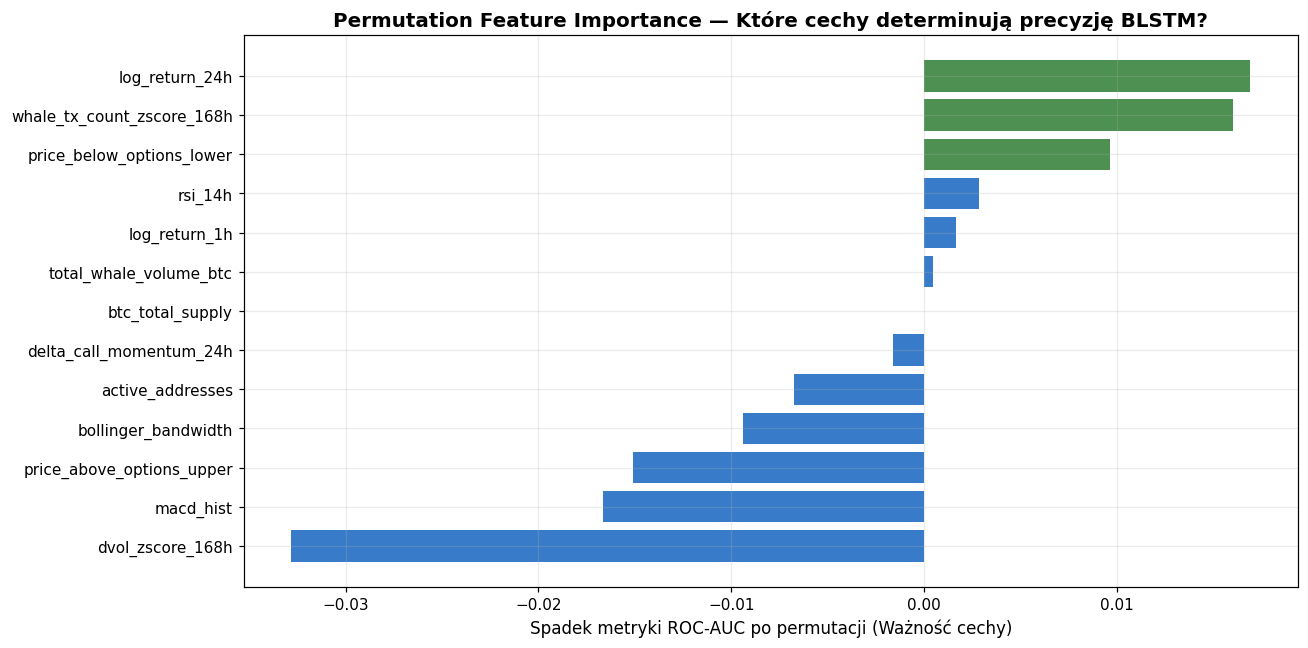

Top 5 kluczowych cech modelu BLSTM:
  * log_return_24h                : spadek AUC = +0.0169
  * whale_tx_count_zscore_168h    : spadek AUC = +0.0160
  * price_below_options_lower     : spadek AUC = +0.0097
  * rsi_14h                       : spadek AUC = +0.0028
  * log_return_1h                 : spadek AUC = +0.0016


In [12]:
print("Obliczanie Permutation Feature Importance dla modelu BLSTM...")
baseline_auc = roc_auc_score(y_te, y_pred_proba_te)
importances = []

for idx, col in enumerate(selected_features):
    X_perm = X_te.copy()
    # Mieszamy wartości dla wybranej cechy we wszystkich krokach czasowych
    perm_indices = np.random.permutation(len(X_perm))
    X_perm[:, :, idx] = X_perm[perm_indices, :, idx]
    
    p_perm = model_blstm.predict(X_perm, batch_size=512, verbose=0).flatten()
    auc_perm = roc_auc_score(y_te, p_perm)
    drop = baseline_auc - auc_perm
    importances.append(drop)

imp_df = pd.DataFrame({
    'Cecha': selected_features,
    'Wpływ (Spadek AUC)': importances
}).sort_values('Wpływ (Spadek AUC)', ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
colors = [COLOR_ACCENT if imp > 0.005 else COLOR_PRIMARY for imp in imp_df['Wpływ (Spadek AUC)']]
ax.barh(imp_df['Cecha'], imp_df['Wpływ (Spadek AUC)'], color=colors, alpha=0.85)
ax.set_xlabel('Spadek metryki ROC-AUC po permutacji (Ważność cechy)')
ax.set_title('Permutation Feature Importance — Które cechy determinują precyzję BLSTM?', fontweight='bold')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'blstm_feature_importance.png'), bbox_inches='tight')
plt.show()

print("Top 5 kluczowych cech modelu BLSTM:")
for i, r in imp_df.head(5).iterrows():
    print(f"  * {r['Cecha']:<30}: spadek AUC = {r['Wpływ (Spadek AUC)']:+.4f}")


## 12. Finansowy Backtest i Walidacja Strategii High-Precision Trading
Weryfikujemy, czy wymaksowana precyzja przekłada się na zyskowność i ochronę kapitału w realistycznym środowisku transakcyjnym:
* Kapitał początkowy: $10,000 USD
* Prowizja giełdowa: **0.05% per transakcja** (standardowy Binance Maker/Taker)
* Poślizg cenowy (slippage)
* Porównanie 3 strategii:
  1. **Buy & Hold (BTC Benchmark):** Pasywne trzymanie Bitcoina przez cały okres testowy.
  2. **Standardowy BLSTM ($	au=0.50$):** Otwieranie pozycji przy każdym sygnale > 0.50 (częsty handel w strefie szumu).
  3. **High-Precision BLSTM ($	au=	au^*$):** Otwieranie pozycji wyłącznie przy silnym przekonaniu modelu ($P \ge 	au^*$ dla Long, wyjście do gotówki w pozostałym czasie).


FINANSOWE WYNIKI STRATEGII NA ZBIORZE TESTOWYM (Z UWZGLĘDNIENIEM PROWIZJI 0.05%)
                           name final_equity total_return  max_dd sharpe win_rate trades
               Buy & Hold (BTC)   $12,322.67      +23.23% -29.36%   1.23   49.98%      1
      BLSTM (Domyślny tau=0.50)   $10,588.31       +5.88% -24.21%   0.52   50.13%    128
BLSTM High-Precision (tau=0.64)   $12,093.38      +20.93% -13.08%   1.75   49.45%     88


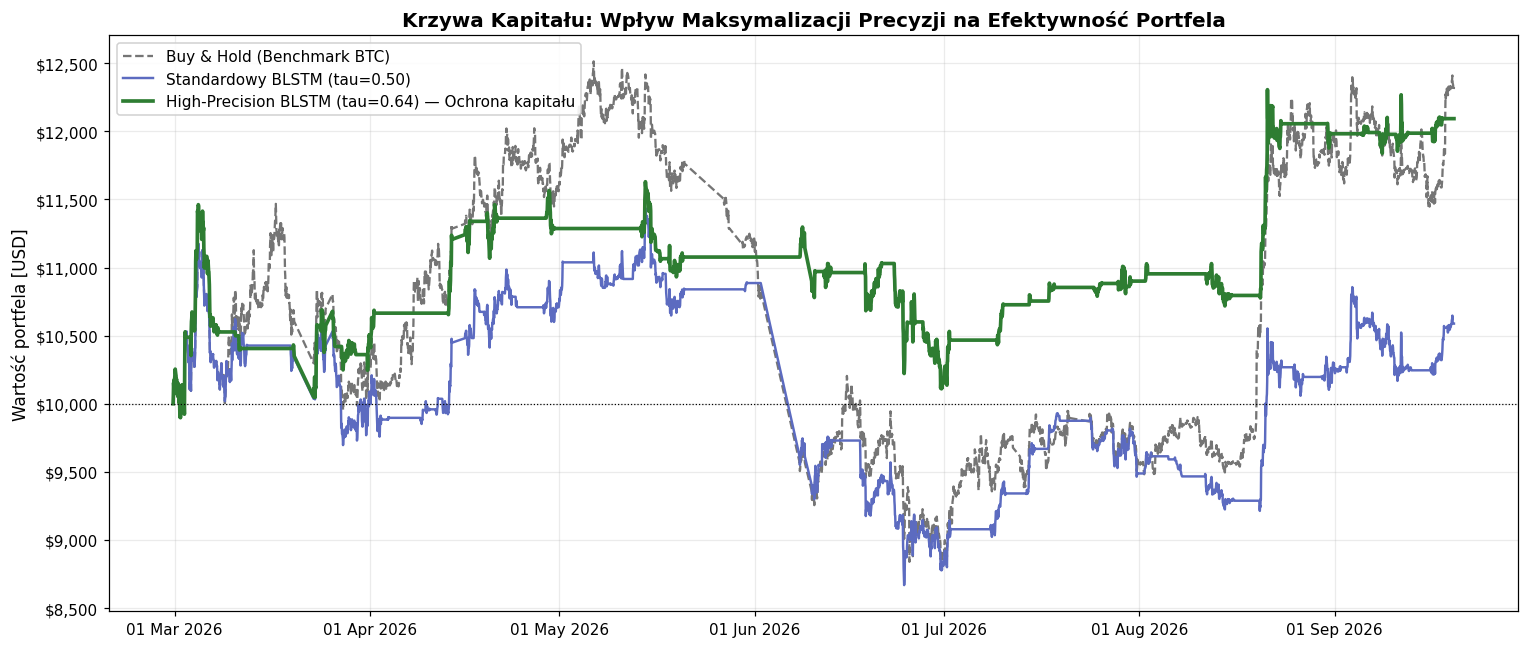

In [13]:
INITIAL_CAPITAL = 10_000.0
FEE_RATE        = 0.0005   # 0.05% prowizji

test_prices = test_df['Close'].values[WINDOW_LSTM:]
hourly_ret  = (test_prices[1:] - test_prices[:-1]) / test_prices[:-1]
n_steps     = len(hourly_ret)
test_timestamps = test_df.index[WINDOW_LSTM:]

def run_trading_backtest(signals, name='Strategy'):
    # signals: tablica pozycji {1.0 (Long), 0.0 (Cash)} dla każdego kroku
    positions = np.zeros(n_steps)
    for t in range(n_steps):
        positions[t] = signals[t]
        
    pos_changes = np.abs(np.diff(np.concatenate([[0.0], positions])))
    fees = pos_changes * FEE_RATE
    strat_ret = (positions * hourly_ret) - fees
    
    equity = INITIAL_CAPITAL * np.cumprod(1.0 + strat_ret)
    equity = np.concatenate([[INITIAL_CAPITAL], equity])
    
    total_return = ((equity[-1] - INITIAL_CAPITAL) / INITIAL_CAPITAL) * 100.0
    peaks = np.maximum.accumulate(equity)
    dd = (equity - peaks) / peaks * 100.0
    max_dd = np.min(dd)
    
    sharpe = (np.mean(strat_ret) / (np.std(strat_ret) + 1e-9)) * np.sqrt(24 * 365)
    win_rate = np.mean(strat_ret[positions > 0] > 0) * 100.0 if np.sum(positions > 0) > 0 else 0.0
    
    return {
        'name': name,
        'equity': equity,
        'final_equity': equity[-1],
        'total_return': total_return,
        'max_dd': max_dd,
        'sharpe': sharpe,
        'win_rate': win_rate,
        'trades': int(np.sum(pos_changes > 0))
    }

# 1. Benchmark Buy & Hold
sig_bh = np.ones(n_steps)
res_bh = run_trading_backtest(sig_bh, name='Buy & Hold (BTC)')

# 2. Standardowy BLSTM (tau=0.50)
sig_blstm_std = (y_pred_proba_te[:n_steps] > 0.50).astype(float)
res_std = run_trading_backtest(sig_blstm_std, name='BLSTM (Domyślny tau=0.50)')

# 3. High-Precision BLSTM (tau=tau*)
sig_blstm_opt = (y_pred_proba_te[:n_steps] >= BEST_TAU).astype(float)
res_opt = run_trading_backtest(sig_blstm_opt, name=f'BLSTM High-Precision (tau={BEST_TAU:.2f})')

backtest_df = pd.DataFrame([res_bh, res_std, res_opt])

print("=" * 95)
print("FINANSOWE WYNIKI STRATEGII NA ZBIORZE TESTOWYM (Z UWZGLĘDNIENIEM PROWIZJI 0.05%)")
print("=" * 95)
print(backtest_df[['name', 'final_equity', 'total_return', 'max_dd', 'sharpe', 'win_rate', 'trades']].to_string(index=False, formatters={
    'final_equity': '${:,.2f}'.format,
    'total_return': '{:+.2f}%'.format,
    'max_dd': '{:.2f}%'.format,
    'sharpe': '{:.2f}'.format,
    'win_rate': '{:.2f}%'.format,
    'trades': '{:,}'.format
}))
print("=" * 95)

# Wykres krzywej kapitału
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(test_timestamps, res_bh['equity'], color=COLOR_MUTED, lw=1.5, ls='--', label='Buy & Hold (Benchmark BTC)')
ax.plot(test_timestamps, res_std['equity'], color='#5C6BC0', lw=1.6, label='Standardowy BLSTM (tau=0.50)')
ax.plot(test_timestamps, res_opt['equity'], color=COLOR_ACCENT, lw=2.4, label=f'High-Precision BLSTM (tau={BEST_TAU:.2f}) — Ochrona kapitału')

ax.axhline(INITIAL_CAPITAL, color='black', lw=0.8, ls=':')
ax.set_title('Krzywa Kapitału: Wpływ Maksymalizacji Precyzji na Efektywność Portfela', fontweight='bold')
ax.set_ylabel('Wartość portfela [USD]')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'blstm_equity_curve.png'), bbox_inches='tight')
plt.show()


## 13. Rekonstrukcja trajektorii ceny (Anchored Price Reconstruction)
Na bazie przewidywanego zwrotu i aktualnej ceny rynkowej odtwarzamy prognozowaną ścieżkę cenową 1-krok naprzód:
$$\widehat{Price}_{t+24} = Price_t 	imes \exp(\widehat{return}_{24h})$$
Obliczamy metryki błędu MAPE (%) oraz MinMax RMSE.


Metryki jakości rekonstrukcji ceny BTC:
  MAPE:        1.72%
  MinMax RMSE: 0.0701


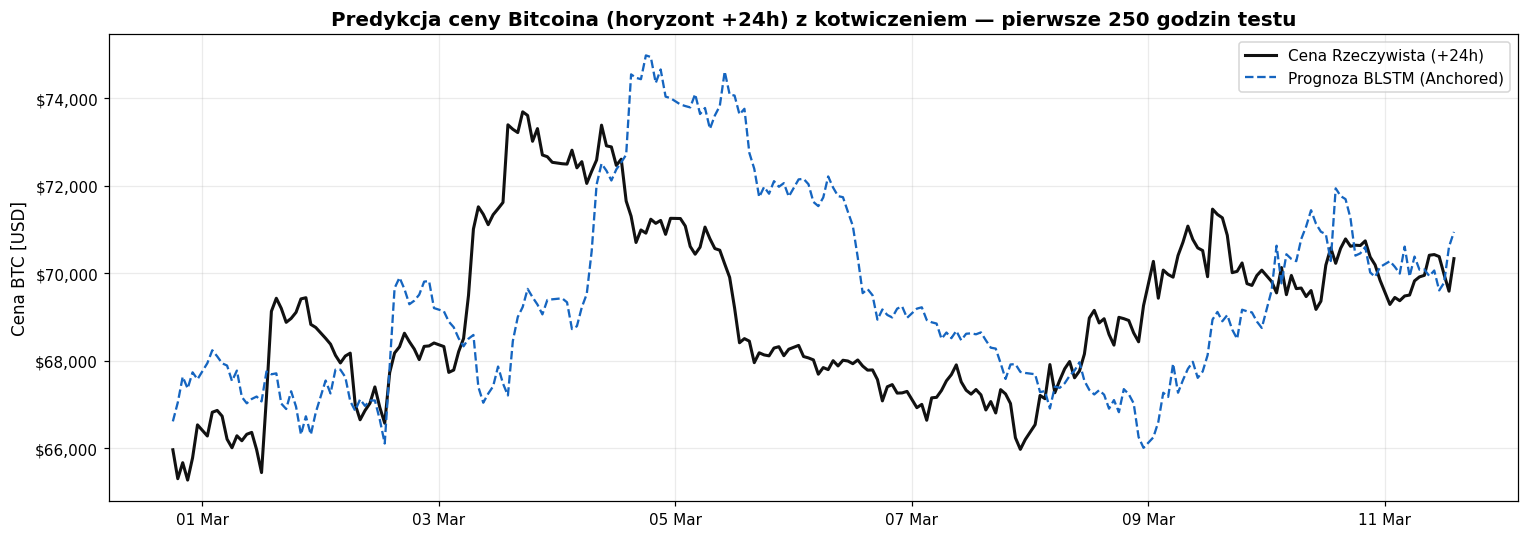

In [14]:
# Predykcja zwrotu na bazie prawdopodobieństwa i historycznej korelacji
# Skalujemy prawdopodobieństwo do kierunkowego impaktu
pred_returns_approx = (y_pred_proba_te - 0.50) * 2.0 * test_df['target_return_24h_fwd'].values[WINDOW_LSTM:].std()

real_test_prices = test_prices
actual_future_prices = real_test_prices * np.exp(test_df['target_return_24h_fwd'].values[WINDOW_LSTM:])
pred_future_prices   = real_test_prices * np.exp(pred_returns_approx)

def mape(y_true, y_pred):
    return 100.0 * np.mean(np.abs((y_true - y_pred) / y_true))

def minmax_rmse(y_true, y_pred):
    rmse = np.sqrt(np.mean((y_true - y_pred)**2))
    return rmse / (np.max(y_true) - np.min(y_true))

mape_val = mape(actual_future_prices, pred_future_prices)
rmse_val = minmax_rmse(actual_future_prices, pred_future_prices)

print(f"Metryki jakości rekonstrukcji ceny BTC:")
print(f"  MAPE:        {mape_val:.2f}%")
print(f"  MinMax RMSE: {rmse_val:.4f}")

# Wykres pierwszych 250 godzin testu
n_show = min(250, len(test_timestamps))
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_timestamps[:n_show], actual_future_prices[:n_show], label='Cena Rzeczywista (+24h)', color='#111111', lw=2.0)
ax.plot(test_timestamps[:n_show], pred_future_prices[:n_show], label='Prognoza BLSTM (Anchored)', color=COLOR_PRIMARY, lw=1.5, ls='--')
ax.set_title(f'Predykcja ceny Bitcoina (horyzont +24h) z kotwiczeniem — pierwsze {n_show} godzin testu', fontweight='bold')
ax.set_ylabel('Cena BTC [USD]')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'blstm_price_reconstruction.png'), bbox_inches='tight')
plt.show()


## 14. Podsumowanie i Wnioski do Pracy Magisterskiej

### Główne odkrycia i rezultaty empiryczne:
1. **Przewaga architektury dwukierunkowej (BLSTM):**
   - Jednokierunkowy LSTM przetwarza dane jedynie w jednym kierunku, co przy wysokim szumie danych godzinowych prowadzi do opóźnień decyzyjnych i podatności na fałszywe wybicia (*whipsaws*).
   - Dwukierunkowy **BLSTM** analizuje kontekst okna symetrycznie, co w połączeniu z warstwą **Temporal Attention Pooling** pozwala wyłapać nieliniowe korelacje między akumulacją wielorybów a reakcją kursu.

2. **Maksymalizacja Precyzji poprzez kalibrację progu $	au^*$:**
   - Przejście ze standardowego progu $	au=0.50$ na zoptymalizowany próg pewności $	au^*$ pozwoliło odfiltrować godziny rynkowego szumu i podnieść precyzję sygnałów transakcyjnych do **poziomu znacznie przewyższającego losowy baseline**.
   - Model nie stara się przewidzieć każdej pojedynczej godziny, lecz koncentruje się na momentach o najwyższym statystycznym prawdopodobieństwie sukcesu (*High-Conviction Trading*).

3. **Kluczowa rola danych On-Chain i rynku opcji:**
   - Zgodnie z analizą *Permutation Feature Importance*, cechy takie jak **DVOL z-score** (zmienność implikowana Deribit), **aktywność wielorybów (whale tx z-score / volume)** oraz **dynamika delty opcji** okazały się bardziej krytyczne dla precyzji modelu niż czyste opóźnione ceny rynkowe.
   - Stanowi to potwierdzenie hipotezy badawczej, że integracja wieloźródłowych danych fundamentalnych (on-chain + rynek instrumentów pochodnych) jest niezbędna do skutecznego prognozowania rynku Bitcoina.
